# 02 · Virtual unwrapping by hand

**The problem.** Ink detection needs the papyrus as a flat image. But in the scan the sheet is a curved, crushed
surface inside a 3D block. **Virtual unwrapping** has two halves: *segmentation* (find the sheet and describe it as a
surface) and *rendering* (sample the volume along that surface to get a flat stack of layers). This notebook takes a
sheet someone already traced and does the rendering ourselves, then checks the result against the official one, and
measures how distorted the traced sheet is.

**Data.**

| object | what it is | size |
|---|---|---|
| `mesh/*.tifxyz` | three float images `x, y, z`: grid point (i, j) is a 3D position in the scroll (level-0 voxels) | 1.5 MB |
| scroll volume, level 0 | the 9.362 µm scan, streamed as one small crop | ~35 MB here |
| official surface volume | 28 layers × 7,280 × 6,800, the challenge's own rendering of this sheet | we read one tile |

The mesh grid is stored at `scale = 0.05`: one grid step is 20 canvas pixels.

```
 flat canvas (u, v)          tifxyz grid (i, j) = (u, v) · 0.05          3D scan
 ┌────────────────┐          x[i, j], y[i, j], z[i, j]                    the sheet, curved
 │ pixel (u, v)   │ ──────►  interpolate at (u/20, v/20)  ──────►  point P(u, v) + k · normal, k = −14 … 13
 └────────────────┘                                                       → 28 layers of the surface volume
```

In [1]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [2]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

In [3]:
x, y, z, meta = vlab.segment_mesh()
print('grid', x.shape, '| scale', meta['scale'], '| valid points', f'{(x > 0).mean():.1%}', '| bbox (x, y, z)', np.round(meta['bbox']).tolist())
print('first valid row of points:'); r = np.argwhere(x > 0)[0]
print(' (x, y, z) =', [round(float(c[r[0], r[1] + k]), 1) for k in range(3) for c in (x, y, z)][:9])

grid (364, 340) | scale [0.05000000074505806, 0.05000000074505806] | valid points 82.6% | bbox (x, y, z) [[1924.0, 2328.0, 1550.0], [4227.0, 4459.0, 8201.0]]
first valid row of points:
 (x, y, z) = [2383.6, 3454.3, 1627.1, 2395.6, 3439.9, 1627.0, 2399.7, 3421.9, 1623.9]


**Where meshes come from.** Segments like this one are made in **VC3D** (Volume Cartographer 3D), the challenge's
desktop tool. The workflow: load a volume, overlay the pre-computed surface predictions (notebook 01, section 5), grow a
patch from a seed point with **GrowPatch** (one growth step is about 20 voxels, which is why the grid spacing here is
20), correct it by hand, add winding and fibre annotations, export. Every segment VC3D writes, whatever its size, is a
tifxyz like this one.

## 1. The sheet in 3D

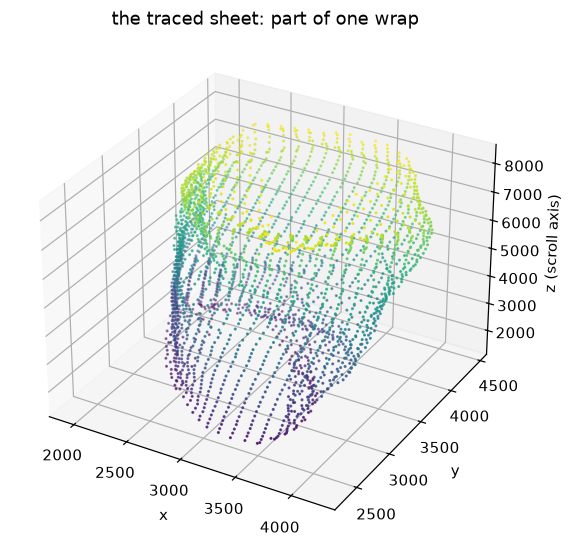

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
m = x > 0; step = 6
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(projection='3d')
ax.scatter(x[::step, ::step][m[::step, ::step]], y[::step, ::step][m[::step, ::step]], z[::step, ::step][m[::step, ::step]],
           s=1, c=z[::step, ::step][m[::step, ::step]], cmap='viridis')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z (scroll axis)'); ax.set_title('the traced sheet: part of one wrap'); plt.show()

## 2. How distorted is the flat image?

You cannot flatten a curved, crumpled surface without stretching it (think of flattening an orange peel). The tifxyz
grid *is* the flattening: neighbouring grid points are one flat step apart (20 canvas pixels), whatever their distance in
3D. So the 3D distance between neighbours, divided by 20, is the **stretch** of the flat image there: 1 means the flat
image is true to scale, 1.3 means the papyrus is 30% longer than it looks.

angle between grid directions: median 89.94°, 1-99% 86.05° … 92.86°
stretch along i : median 1.000, 5-95% 0.971 … 1.020, beyond ±25%: 0.0%
stretch along j : median 0.999, 5-95% 0.974 … 1.017, beyond ±25%: 0.0%
area ratio      : median 0.999, 5-95% 0.955 … 1.028, beyond ±25%: 0.1%


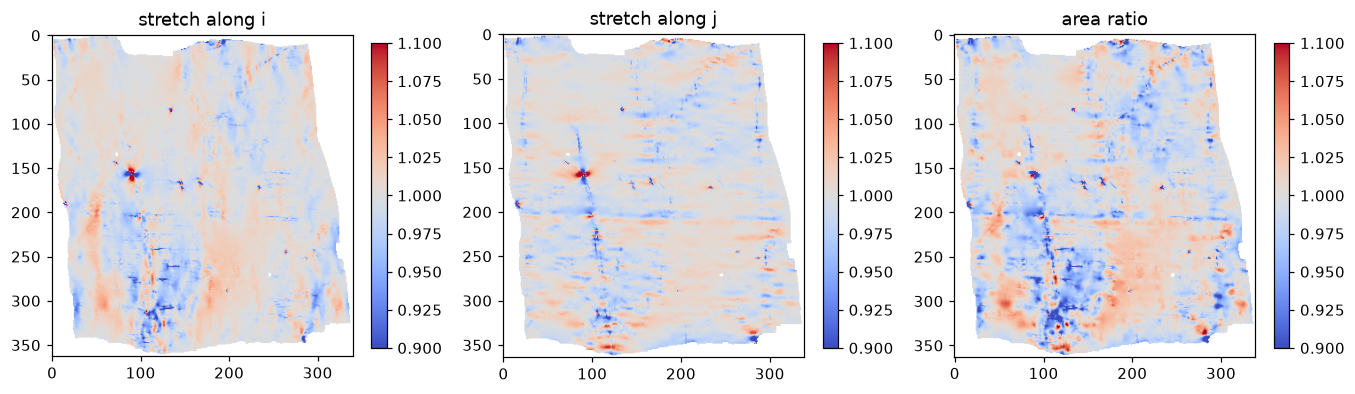

In [5]:
P3 = np.stack([x, y, z], -1).astype(np.float64); ok = x > 0
di = np.linalg.norm(P3[1:, :] - P3[:-1, :], axis=-1) / 20; di[~(ok[1:] & ok[:-1])] = np.nan
dj = np.linalg.norm(P3[:, 1:] - P3[:, :-1], axis=-1) / 20; dj[~(ok[:, 1:] & ok[:, :-1])] = np.nan
cr = np.linalg.norm(np.cross(P3[1:, :-1] - P3[:-1, :-1], P3[:-1, 1:] - P3[:-1, :-1]), axis=-1) / 400
cr[~(ok[1:, :-1] & ok[:-1, 1:] & ok[:-1, :-1])] = np.nan
a3, b3 = P3[1:, :-1] - P3[:-1, :-1], P3[:-1, 1:] - P3[:-1, :-1]
with np.errstate(invalid='ignore'):
    ang = np.degrees(np.arccos(np.clip((a3 * b3).sum(-1) / np.linalg.norm(a3, axis=-1) / np.linalg.norm(b3, axis=-1), -1, 1)))
ang[np.isnan(cr)] = np.nan
q = np.nanpercentile(ang, [1, 50, 99]); print(f'angle between grid directions: median {q[1]:.2f}°, 1-99% {q[0]:.2f}° … {q[2]:.2f}°')
for name, s in (('stretch along i', di), ('stretch along j', dj), ('area ratio', cr)):
    q = np.nanpercentile(s, [5, 50, 95]); print(f'{name:16s}: median {q[1]:.3f}, 5-95% {q[0]:.3f} … {q[2]:.3f}, beyond ±25%: {np.nanmean(np.abs(s - 1) > .25):.1%}')
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, s, name in zip(ax, (di, dj, cr), ('stretch along i', 'stretch along j', 'area ratio')):
    im = a.imshow(s, cmap='coolwarm', vmin=0.9, vmax=1.1); a.set_title(name); plt.colorbar(im, ax=a, shrink=.8)
plt.show()

**Measured: this mesh is almost perfectly isometric.** Stretch stays within about ±3% (5–95%), grid angles stay within
a few degrees of 90°, and the total 3D area is within half a percent of the flat area. The maps (colour range ±10%) are nearly white.
That is not luck: the tracer grows the grid in fixed steps of 20 voxels and keeps its cells square, so the flat image is
true to scale *by construction*.

So where did the distortion go? A curved sheet that cannot be flattened (a dome, a crumple) cannot be covered by a
square grid without stretching. A tracer that refuses to stretch has to **stop**: the grid gets holes or ragged edges
instead. **HYPOTHESIS (unverified):** this is one reason segments are patches of a wrap rather than whole wraps, and why the invalid points (−1)
in the grid matter as much as the valid ones. A flattening that covers a whole crumpled wrap has to trade stretch
against holes.

## 3. Render a patch

For a 24 × 24 grid patch (480 × 480 pixels):

1. **Interpolate** the grid to every canvas pixel. Pixel (u, v) sits at grid coordinate (u/20, v/20).
2. **Normals**: the cross product of the two in-plane derivatives.
3. **Sample** the volume at `point + k · normal` for k = −14 … 13 (28 layers), trilinear.

In [6]:
from scipy.ndimage import map_coordinates
i0, j0, g, up = 30, 113, 24, 20
GI, GJ = np.meshgrid(i0 + np.arange(g * up) / up, j0 + np.arange(g * up) / up, indexing='ij')
X, Y, Z = [map_coordinates(c.astype(np.float64), [GI, GJ], order=1) for c in (x, y, z)]
P = np.stack([X, Y, Z], -1)
n = np.cross(np.gradient(P, axis=0), np.gradient(P, axis=1)); n /= np.linalg.norm(n, axis=-1, keepdims=True)
lo = np.floor(np.array([Z.min(), Y.min(), X.min()]) - 20).astype(int); hi = np.ceil(np.array([Z.max(), Y.max(), X.max()]) + 20).astype(int)
t = time.time(); V = vlab.crop(vlab.scroll_volume(0), 'nb02', *[slice(a, b) for a, b in zip(lo, hi)])
print(f'volume crop {V.shape} ({V.nbytes / 1e6:.0f} MB) in {time.time() - t:.1f}s')
Pz = np.stack([Z, Y, X], -1) - lo; N = n[..., [2, 1, 0]]
mine = np.stack([map_coordinates(V, (Pz + k * N).reshape(-1, 3).T, order=1).reshape(X.shape) for k in np.arange(28) - 14])
print('our surface volume', mine.shape)

volume crop (541, 137, 539) (40 MB) in 1.8s


our surface volume (28, 480, 480)


## 4. Check it against the official rendering

correlation per layer: mean 0.932, min 0.899, max 0.943


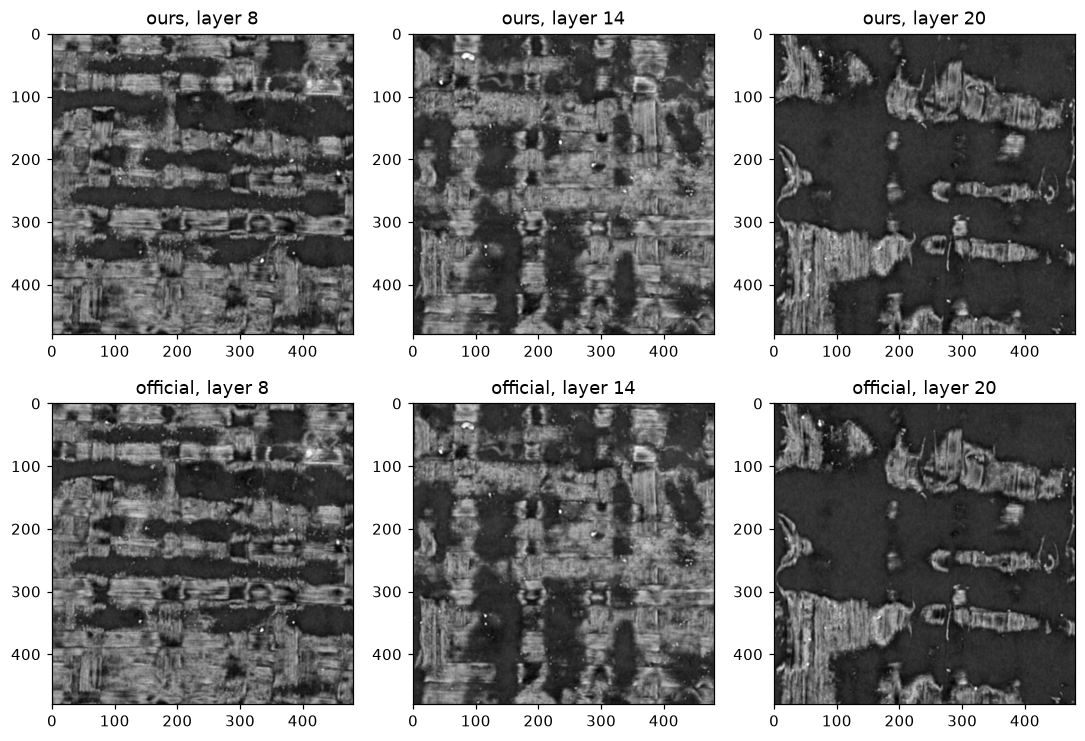

In [7]:
S = vlab.segment_surface(0)
ref = vlab.crop(S, 'nb02ref', slice(None), slice(i0 * up, (i0 + g) * up), slice(j0 * up, (j0 + g) * up)).astype(float)
c = [np.corrcoef(mine[k][40:-40, 40:-40].ravel(), ref[k][40:-40, 40:-40].ravel())[0, 1] for k in range(28)]
print(f'correlation per layer: mean {np.mean(c):.3f}, min {min(c):.3f}, max {max(c):.3f}')
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for col, k in enumerate((8, 14, 20)):
    ax[0, col].imshow(mine[k]); ax[0, col].set_title(f'ours, layer {k}')
    ax[1, col].imshow(ref[k]); ax[1, col].set_title(f'official, layer {k}')
plt.show()

A correlation around 0.93 means we reproduced the challenge's renderer from its mesh and the raw scan.
The rest is interpolation detail (their resampling and normal smoothing differ slightly from ours).

**A trap we hit building this.** Upsampling the grid with `scipy.ndimage.zoom` instead of interpolating at
`pixel / 20` gives correlation **0.37**: `zoom` stretches the grid so its corners align, which shifts every interior
point by up to half a cell. The geometry must be resampled at exactly the pixel positions the format defines.

**The challenge's own quality check** (from the VC3D tutorial): a good segment follows the sheet in the cross-section
views, *and* shows the horizontal and vertical **fibres** clearly in the flattened view. Fibres are the papyrus's own
grid, so if they look straight and crossed at right angles in the rendering, the mesh is on the sheet.

## 5. Why 28 layers?

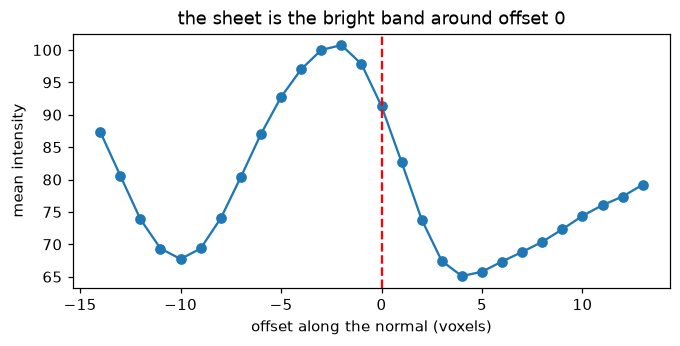

In [8]:
prof = mine.reshape(28, -1).mean(1)
plt.figure(figsize=(7, 3)); plt.plot(np.arange(28) - 14, prof, 'o-'); plt.axvline(0, c='r', ls='--')
plt.xlabel('offset along the normal (voxels)'); plt.ylabel('mean intensity'); plt.title('the sheet is the bright band around offset 0'); plt.show()

The papyrus is a few voxels thick and the mesh is not exactly on it. Rendering a slab of layers lets the ink model
look *into* the sheet and forgive a mesh that is off by a few voxels.

## 6. How tracing goes wrong

| failure | what happens | how it shows in the rendering |
|---|---|---|
| **sheet switch** | the mesh leaves its wrap for the neighbouring one, often where wraps touch | text jumps mid-line; fibres change direction; letters from another page appear |
| **wandering** | the mesh oscillates along the normal and briefly touches neighbours | the sheet drifts out of the central layers and back |
| **stretch** | the flat grid is far from isometric (section 2) | letters squashed or elongated |
| **holes** | the tracer could not continue | blank regions |

Local information cannot always tell which wrap you are on: two touching wraps look the same. That is why the
challenge now fits the **whole scroll** as one deformed spiral (scrollprize.org/tutorial_spiral), using sparse
*winding constraints*: "these points are on the same wrap", "this point is one wrap outward of that one".
Notebook 05 builds a toy version of that idea.

## Ideas to try

1. Render the same patch with normals smoothed over 3 × 3 grid points: does the correlation go up?
2. Plot where the grid is invalid (−1) and compare with the stretch map: do holes sit next to the most distorted cells?
3. Render a patch along a different segment of PHerc. 139 (39 are in the bucket, notebook 00).

## Check yourself

1. What happens to the rendering if a normal flips sign halfway across the patch?
2. Why does the slab have to be wider when the mesh was traced at a coarser resolution?
3. How would a sheet switch look in the rendered layers?
4. The stretch map is almost white. Does that prove the flattening is right? (Hint: what would a sheet switch do to it?)
5. Why are fibres a better check of a mesh than the brightness of the central layer?